# 문서 처리 실습: 형식이 다른 문서를 한 색인에 모아 찾기

**이 노트북에서 할 일**

1. PDF·DOCX·HWPX 견본 세 개를 형식마다 다른 방법으로 읽어 출처 기록을 붙입니다.
2. 기록을 보고 표시 함수를 골라 주는 함수 하나로 세 형식의 출처 표시를 만듭니다.
3. PDF 한 건만 넣은 색인과 세 형식을 함께 넣은 색인에서 같은 질문을 검색해 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 네 번입니다. 색인 두 벌에 두 번, 검색 두 번에 두 번입니다.
답을 쓰는 모델은 이 절에서도 부르지 않습니다.

예상 비용은 네 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

데이터는 세 개입니다.
파일 `labs/data/rag-corpus/pdf/easy/E01.pdf`의 2쪽을 읽습니다.
실습 폴더 `fixtures/`의 `sample.docx`와 `minimal-marker.hwpx`도 함께 읽습니다.

이 노트북은 파일을 만들거나 고치지 않습니다.
08절이 쓴 `runs` 폴더의 기록 파일은 읽지도 건드리지도 않습니다.

**강의와 실습 범위** — 강사와 함께 첫 셀부터 차례로 실행합니다. 따로 내는 과제는 없습니다.
함수를 만드는 셀은 세 개입니다. 앞 절에서 배운 함수 일곱 개는 도구 파일에서 가져옵니다.
3절의 읽기 결과와 5절의 출처 표시, 7~9절의 점검표를 함께 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다.
pypdf 6.18.0과 python-docx 1.2.0, langchain-core 1.6.2를 씁니다.
나누기 도구는 langchain-text-splitters 1.1.2입니다. 임베딩은 langchain-openai 1.6.0으로 부릅니다.
조각은 tiktoken 0.14.0으로 셉니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 내려가는 흐름도로 초록 상자 재료 문서 세 개 PDF 2쪽 905자 DOCX 27자 HWPX 15자에서 파란 상자 기록 붙이기 make_source_record make_unit_record로 내려가고 파란 상자 출처 표시 고르기 pick_mark를 지나 파란 상자 run_index 재귀 200자 색인 검색 5줄로 이어진 뒤 문서 청크와 질문 화살표로 보라 상자 text-embedding-3-small 실행마다 요청 2번과 노란 상자 print_hit_rows 순위 출처 표시 글자 수 점수로 갈라지는 그림](attachment:09-1-조립도.png)

위에서 아래로 읽습니다. 맨 위 초록 상자는 노트북 3절에서 만드는 재료입니다.
파란 상자 세 개는 노트북에서 정의하는 함수이고, 보라 상자는 요청을 받는 임베딩 모델입니다.

맨 아래 노란 상자가 검색 결과를 점검표로 출력합니다. 두 실행은 색인에 넣는 문서 묶음 하나만 다릅니다.
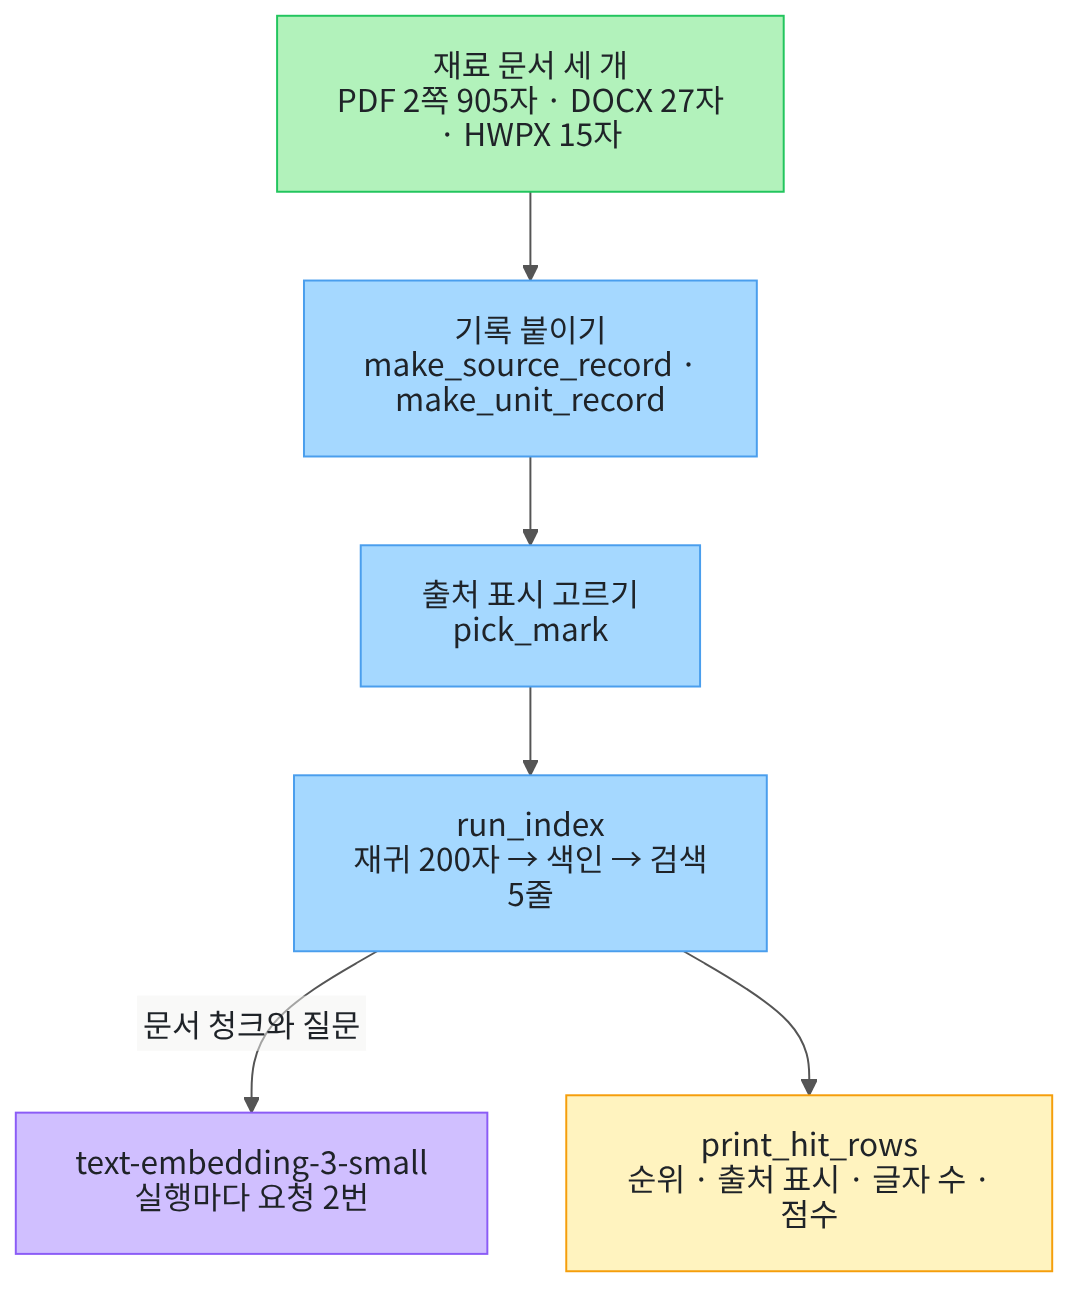

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01·03·04·05·07절에서 쓴 도구를 함께 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "python-docx==1.2.0" "langchain-core==1.6.2" "langchain-text-splitters==1.1.2" "langchain-openai==1.6.0" "tiktoken==0.14.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("python-docx:", version("python-docx"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("langchain-openai:", version("langchain-openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0


python-docx: 1.2.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
langchain-openai: 1.6.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 일곱 줄 가운데 첫 줄은 `pypdf: 6.18.0`입니다.
둘째 줄 `python-docx: 1.2.0`과 다섯째 줄 `langchain-openai: 1.6.0`도 보세요.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
클래스 `DocxDocument`는 03절에서 다른 이름을 붙여 부른 python-docx의 문서 객체입니다.
모듈 `zipfile`과 `ElementTree`는 04절에서 HWPX를 열 때 쓴 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 9 02·03절 `load_pdf_pages()`·`make_source_mark()`와 01절 `make_source_record()`를 가져옵니다.
03절 `make_unit_record()`·`make_unit_mark()`와 04절 `read_body_text()`·`make_section_mark()`도 가져옵니다.

In [2]:
# 세 형식 읽기·기록·나누기·임베딩·색인·조각 세기에 쓸 이름을 불러옵니다
import os
import zipfile
from xml.etree import ElementTree

from docx import Document as DocxDocument
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken
# 01·03·04절과 Ch 9 02·03절 함수 일곱 개를 도구 파일에서 가져옵니다
from rag_tools import load_pdf_pages, make_section_mark, make_source_mark, make_source_record
from rag_tools import make_unit_mark, make_unit_record, read_body_text

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 노트북의 출력은 2026-09-21에 `text-embedding-3-small` 모델로 실행한 결과입니다.

## 2. 실습 주제 — 형식이 다른 문서를 한 색인에 모아 찾기

작은 안내 창구를 하나 맡았다고 봅니다.
그 창구가 가진 자료는 형식이 다릅니다. 도서관 안내는 PDF이고, 배송 안내는 DOCX이고, 한글 문서 표식은 HWPX입니다.
01~04절에서는 이 형식을 하나씩 따로 읽었고, 05~08절에서는 PDF 하나만 나누고 색인에 넣었습니다.

이번 실습은 세 형식을 한 색인에 함께 넣어 봅니다.
질문은 하나이고, 두 번 실행하며 바꾸는 값도 하나입니다. 색인에 넣는 문서 묶음입니다.

실행 1은 앞 절과 같이 PDF 한 건만 넣습니다.
실행 2는 같은 색인 설정에 DOCX와 HWPX를 더해 넣습니다.
나누기 설정과 질문, 검색 개수, 임베딩 모델은 두 실행에서 같게 둡니다.

## 3. 재료 만들기 — 형식이 다른 문서 세 개 읽기

먼저 프로젝트 맨 위 경로를 고릅니다. 01~08절과 같은 코드입니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [4]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 읽을 파일 세 개의 경로를 만들고 파일이 있는지 봅니다.
이름 `corpus_path`와 `fixtures_path`는 01절에서 정한 이름입니다.

In [5]:
# 읽을 파일 세 개의 경로를 만들고 파일이 있는지 확인합니다
corpus_path = root_path + "/labs/data/rag-corpus"
fixtures_path = root_path + "/labs/part3/ch10-document-processing/fixtures"
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
docx_path = fixtures_path + "/sample.docx"
hwpx_path = fixtures_path + "/minimal-marker.hwpx"
print("PDF가 있는가:", os.path.exists(pdf_path))
print("DOCX 견본이 있는가:", os.path.exists(docx_path))
print("HWPX 견본이 있는가:", os.path.exists(hwpx_path))

PDF가 있는가: True
DOCX 견본이 있는가: True
HWPX 견본이 있는가: True


**결과 읽기** — 출력 세 줄이 모두 `True`입니다.
이 PDF는 01·02절과 05~08절에서 읽은 그 문서입니다.
견본 두 개는 03·04절에서 읽은 그 파일입니다.

문서 E01은 준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`로 읽습니다.

다음 셀은 그 함수로 다섯 쪽을 읽고 2쪽 본문만 골라 둡니다.
05·06·07절이 나눈 그 글입니다. 쪽이 있는 형식이라 쪽 번호를 그대로 쓸 수 있습니다.

In [6]:
# E01.pdf 다섯 쪽을 읽고 2쪽 본문만 골라 둡니다
pages = load_pdf_pages(pdf_path, "E01")
plain_text = pages[1].page_content
print("Document 수:", len(pages))
print("2쪽 글자 수:", len(plain_text))
print("2쪽 메타데이터:", pages[1].metadata)

Document 수: 5
2쪽 글자 수: 905
2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}


**결과 읽기** — 출력 첫 줄은 `Document 수: 5`이고 다음 줄은 `2쪽 글자 수: 905`입니다.
셋째 줄 `2쪽 메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`를 보세요.
05·06·07절에서 읽은 값과 같습니다.

다음 셀은 03절 방법으로 DOCX 견본의 문단 글을 이어 붙입니다.
문단마다 줄바꿈을 넣어 한 글로 만듭니다. 표는 다른 목록에 있어 이번에는 읽지 않습니다.

In [7]:
# DOCX 견본의 문단 글을 줄바꿈으로 이어 붙여 한 글로 만듭니다(03절 3절과 같은 읽기)
docx_file = DocxDocument(docx_path)
docx_text = ""
for paragraph in docx_file.paragraphs:
    docx_text = docx_text + paragraph.text + "\n"
print("문단 수:", len(docx_file.paragraphs))
print("이어 붙인 글자 수:", len(docx_text))
print("DOCX 본문:")
print(docx_text)

문단 수: 2
이어 붙인 글자 수: 27
DOCX 본문:
배송 안내
제주 배송에는 이틀이 더 필요합니다.



**결과 읽기** — 출력 첫 줄은 `문단 수: 2`이고 다음 줄은 `이어 붙인 글자 수: 27`입니다.
라벨 줄 `DOCX 본문:` 아래에 `배송 안내`와 `제주 배송에는 이틀이 더 필요합니다.` 두 줄이 보입니다.
03절에서 본 두 문단입니다. 이 글에는 쪽 번호가 없습니다.

HWPX 본문 글은 준비 셀에서 가져온 04절 `read_body_text()`로 모읍니다.
이 함수는 요소 나무를 돌며 찾는 이름의 요소에서 글만 모읍니다.
함수 안에서는 04절 `make_local_name()`이 태그 이름의 이름 공간을 뗍니다.

다음 셀은 HWPX 견본을 압축 묶음으로 열어 본문 XML을 꺼내고 글을 모읍니다.
항목 이름 `Contents/section0.xml`은 04절 6절에서 확인한 이름입니다.

In [8]:
# HWPX 견본의 본문 XML을 꺼내 t 요소의 글만 모읍니다(04절 6~8절과 같은 방법)
wanted_name = "t"
with zipfile.ZipFile(hwpx_path) as archive:
    xml_bytes = archive.read("Contents/section0.xml")
xml_root = ElementTree.fromstring(xml_bytes)
hwpx_text = read_body_text(xml_root, wanted_name)
print("꺼낸 바이트 수:", len(xml_bytes))
print("HWPX 본문 글자 수:", len(hwpx_text))
print("HWPX 본문:", hwpx_text)

꺼낸 바이트 수: 204
HWPX 본문 글자 수: 15
HWPX 본문: 한글 문서 처리 실습입니다.


**결과 읽기** — 출력 첫 줄은 `꺼낸 바이트 수: 204`이고 다음 줄은 `HWPX 본문 글자 수: 15`입니다.
셋째 줄은 `HWPX 본문: 한글 문서 처리 실습입니다.`입니다. 04절에서 읽은 글과 같습니다.

이 글에도 쪽 번호가 없습니다. 대신 본문 XML이 몇 번째 자리인지 적을 수 있습니다.

## 4. 출처 기록 붙이기

이제 세 글에 기록을 붙입니다. 쪽이 있는 형식과 없는 형식이 기록 모양이 다릅니다.
01절 함수는 다섯 칸을 만들고, 03·04절 함수는 네 칸을 만듭니다.

두 함수는 준비 셀에서 가져온 01절 `make_source_record()`와 03절 `make_unit_record()`입니다.

다음 셀은 세 기록을 만듭니다.
HWPX 기록에는 04절에서 정한 자리 칸 `section`을 하나 더 대입합니다.

In [9]:
# 세 글의 출처 기록을 만들고 HWPX 기록에는 자리 칸을 하나 더합니다
pdf_record = make_source_record(pdf_path, 2, "pypdf-plain")
docx_record = make_unit_record(docx_path, "python-docx")
hwpx_record = make_unit_record(hwpx_path, "zip-xml")
hwpx_record["section"] = 1
print("PDF 기록:", pdf_record)
print("DOCX 기록:", docx_record)
print("HWPX 기록:", hwpx_record)

PDF 기록: {'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pypdf-plain', 'page': 2}
DOCX 기록: {'doc_id': 'sample', 'source': 'sample.docx', 'file_type': 'docx', 'parser': 'python-docx'}
HWPX 기록: {'doc_id': 'minimal-marker', 'source': 'minimal-marker.hwpx', 'file_type': 'hwpx', 'parser': 'zip-xml', 'section': 1}


**결과 읽기** — 출력 첫 줄에 `'page': 2`가 있고 둘째 줄에는 그 칸이 없습니다.
둘째 줄은 `DOCX 기록: {'doc_id': 'sample', 'source': 'sample.docx', 'file_type': 'docx', 'parser': 'python-docx'}`입니다.
셋째 줄 끝에 `'section': 1`이 붙어 있습니다.

칸 `doc_id`는 파일 이름 앞부분입니다. 세 값이 `E01`·`sample`·`minimal-marker`로 서로 다릅니다.
같은 폴더의 견본 세 개는 `doc_id`가 모두 `sample`이라 03절 b7에 갈라 두는 방법을 적어 두었습니다.

다음 셀은 기록을 메타데이터로 삼아 `Document` 세 개를 만듭니다.

In [10]:
# 세 글과 세 기록으로 Document를 만들어 한 목록에 모읍니다
pdf_document = Document(page_content=plain_text, metadata=pdf_record)
docx_document = Document(page_content=docx_text, metadata=docx_record)
hwpx_document = Document(page_content=hwpx_text, metadata=hwpx_record)
mixed_documents = [pdf_document, docx_document, hwpx_document]
print("모은 Document 수:", len(mixed_documents))
print("PDF 기록의 칸 수:", len(pdf_document.metadata))
print("DOCX 기록의 칸 수:", len(docx_document.metadata))
print("HWPX 기록의 칸 수:", len(hwpx_document.metadata))

모은 Document 수: 3
PDF 기록의 칸 수: 5
DOCX 기록의 칸 수: 4
HWPX 기록의 칸 수: 5


**결과 읽기** — 출력 첫 줄은 `모은 Document 수: 3`입니다.
다음 세 줄은 칸 수 `5`·`4`·`5`입니다. DOCX 기록만 한 칸 적습니다.
그 형식에는 자리를 적을 칸을 두지 않았기 때문입니다.

## 5. 출처 표시를 고르는 함수

이 챕터에는 출처 표시를 만드는 함수가 세 개 있습니다.
Ch 9 03절 함수는 `page` 칸을 읽고, 03절 함수는 `row` 칸을, 04절 함수는 `section` 칸을 읽습니다.
형식이 섞인 색인에서는 문서 청크마다 어느 함수를 쓸지 골라야 합니다.

세 함수는 준비 셀에서 가져왔습니다. 03·04절 함수는 자리 칸이 없으면 파일 형식까지만 표시에 붙입니다.

다음 셀이 이 실습의 첫 조립입니다.
기록에 어떤 칸이 있는지 보고 세 함수 가운데 하나를 골라 부릅니다.
칸을 보는 순서는 `page`·`section`·`row`입니다. 실습 폴더 모듈이 문서 청크 이름을 만들 때 쓰는 순서와 같습니다.

In [11]:
# 기록에 있는 칸을 보고 01·04·03절 표시 함수 가운데 하나를 골라 부릅니다
def pick_mark(chunk):
    if "page" in chunk.metadata:
        return make_source_mark(chunk)
    if "section" in chunk.metadata:
        return make_section_mark(chunk)
    return make_unit_mark(chunk)

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

문장 `return`이 셋 있습니다. 앞의 조건이 맞으면 그 자리에서 값을 내보내고 함수가 끝납니다.
그래서 `page` 칸이 있는 기록은 뒤의 두 조건을 보지 않습니다.

다음 셀은 세 `Document`를 이 함수에 넘겨 표시를 받습니다.

실행 전에 예상합니다. 세 표시가 서로 다른 모양으로 나올 것입니다.

In [12]:
# 세 Document의 출처 표시를 한 번에 만들어 봅니다
pdf_mark = pick_mark(pdf_document)
docx_mark = pick_mark(docx_document)
hwpx_mark = pick_mark(hwpx_document)
print("PDF 표시:", pdf_mark)
print("DOCX 표시:", docx_mark)
print("HWPX 표시:", hwpx_mark)

PDF 표시: [E01 p.2]
DOCX 표시: [sample docx]
HWPX 표시: [minimal-marker hwpx section.1]


**결과 읽기** — 출력 첫 줄은 `PDF 표시: [E01 p.2]`입니다.
다음 줄은 `DOCX 표시: [sample docx]`이고 셋째 줄은 `HWPX 표시: [minimal-marker hwpx section.1]`입니다.
01·03·04절에서 각각 본 세 모양이 한 셀에서 함께 나왔습니다.

표시 모양이 형식마다 다릅니다. 쪽이 있으면 쪽 번호가, 자리 칸이 있으면 그 번호가 붙습니다.
DOCX 표시에는 자리 번호가 없어 문서와 형식까지만 알려 줍니다.

## 6. 조립 — 나누고 색인에 넣고 검색하기

요청을 보내기 전에 몇 조각을 보낼지 어림합니다. 06·07·08절과 같은 방식입니다.
색인을 두 벌 만드니 글을 두 번 보냅니다.

In [13]:
# 세 글의 조각 수를 세고 색인 두 벌이 보낼 조각 수와 비용을 어림합니다
encoding = tiktoken.get_encoding("cl100k_base")
all_text = plain_text + docx_text + hwpx_text
all_tokens = encoding.encode(all_text)
index_times = 2
sent_tokens = len(all_tokens) * index_times
embedding_rate = 0.02
tokens_per_million = 1000000
total_cost = round(sent_tokens / tokens_per_million * embedding_rate, 7)
print("세 글을 이은 글자 수:", len(all_text))
print("세 글의 조각 수:", len(all_tokens))
print("색인 두 벌이 보낼 조각 수 어림:", sent_tokens)
print("이 절 전체의 비용 어림(달러):", total_cost)

세 글을 이은 글자 수: 947
세 글의 조각 수: 905
색인 두 벌이 보낼 조각 수 어림: 1810
이 절 전체의 비용 어림(달러): 3.62e-05


**결과 읽기** — 출력 첫 줄은 `세 글을 이은 글자 수: 947`이고 다음 줄은 `세 글의 조각 수: 905`입니다.
셋째 줄 `색인 두 벌이 보낼 조각 수 어림: 1810`이 색인 쪽 어림입니다.
넷째 줄은 `이 절 전체의 비용 어림(달러): 3.62e-05`입니다.

요금은 100만 조각당 0.02달러로 잡았습니다. 코드로 센 어림이고 청구 금액이 아닙니다.
질문을 보내는 요청은 조각 수가 적어 어림에서 뺐습니다.

다음 셀은 질문과 검색 설정을 정합니다. 두 실행에서 같게 둘 값입니다.

In [14]:
# 질문과 검색 개수, 나누기 설정을 정합니다(두 실행에서 같게 둡니다)
question_text = "제주로 보내는 배송은 며칠이 더 걸리나요?"
search_count = 5
chunk_target = 200
chunk_overlap = 0
print("질문:", question_text)
print("검색 개수:", search_count)
print("목표 크기와 겹침:", chunk_target, chunk_overlap)

질문: 제주로 보내는 배송은 며칠이 더 걸리나요?
검색 개수: 5
목표 크기와 겹침: 200 0


**결과 읽기** — 출력 첫 줄은 `질문: 제주로 보내는 배송은 며칠이 더 걸리나요?`입니다.
다음 줄은 `검색 개수: 5`이고 셋째 줄은 `목표 크기와 겹침: 200 0`입니다.

질문은 DOCX 견본에만 답이 있는 내용입니다. 05~08절에서 쓴 휴관일 질문과 다릅니다.
고른 까닭은 본문 「주의할 점과 실무 메모」에 적었습니다.

다음 셀은 임베딩 모델과 나누기 도구를 준비합니다.
모델 이름과 끊을 자리 순서는 앞 절에서 정한 값을 그대로 씁니다.

In [15]:
# 임베딩 모델과 재귀 방식 나누기 도구를 준비합니다(이 셀은 요청을 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
separator_order = ["\n\n", ". ", "\n", " ", ""]
splitter = RecursiveCharacterTextSplitter(
    separators=separator_order, chunk_size=chunk_target,
    chunk_overlap=chunk_overlap, keep_separator="end",
)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("끊을 자리 순서:", separator_order)

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
끊을 자리 순서: ['\n\n', '. ', '\n', ' ', '']


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
다음 줄 `차원 수를 주었는가: False`는 인자 `dimensions`를 주지 않았다는 뜻입니다.
셋째 줄 `끊을 자리 순서: ['\n\n', '. ', '\n', ' ', '']`은 05·07절에서 쓴 순서입니다.

07절에서 만든 숫자 256개짜리 벡터는 여기에 쓰지 않습니다. 08절 색인과 같은 기본 설정입니다.

다음 셀이 이 실습의 두 번째 조립입니다.
문서 목록과 나누기 도구를 받아 나누고, 색인에 넣고, 질문으로 검색합니다.

In [16]:
# 문서 목록을 나눠 색인에 넣고 질문으로 검색해 결과를 모아 반환합니다(임베딩 요청 2번)
def run_index(index_documents, index_splitter):
    chunk_documents = index_splitter.split_documents(index_documents)
    store = InMemoryVectorStore(embedding=embedding_model)
    store.add_documents(chunk_documents)
    hits = store.similarity_search_with_score(question_text, k=search_count)
    return {"chunk_count": len(chunk_documents), "chunks": chunk_documents, "hits": hits}

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

함수 안에서 하는 일은 네 가지입니다.
문서를 나누고, 빈 색인을 만들고, 문서 청크를 넣고, 질문으로 상위 다섯 줄을 받습니다.
넣을 때 요청이 한 번, 검색할 때 또 한 번 생깁니다. 08절 6절에서 확인한 자리입니다.

다음 셀은 검색 결과를 점검표 한 줄씩으로 출력하는 함수를 만듭니다.

In [17]:
# 검색 결과를 순위·출처 표시·글자 수·점수·첫 열두 글자 순서로 한 줄씩 출력합니다
def print_hit_rows(hits):
    rank = 1
    for hit, score in hits:
        head = hit.page_content[:12].replace("\n", " ")
        source_mark = pick_mark(hit)
        print(rank, "|", source_mark, "|", len(hit.page_content), "|", round(score, 2), "|", head)
        rank = rank + 1

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

첫 열두 글자는 줄바꿈을 빈칸으로 바꿔 한 줄에 담았습니다.
점수는 소수 둘째 자리까지만 남깁니다. 아래 자리는 실행마다 달라질 수 있습니다.

## 7. 실행 1 — 색인에 PDF 한 건

첫 실행은 앞 절과 같습니다. PDF 2쪽 글만 나눠 색인에 넣습니다.

실행 전에 예상합니다. 05절에서 본 대로 문서 청크가 6개일 것입니다.

In [18]:
# 실행 1: PDF 한 건만 색인에 넣고 질문으로 검색합니다(임베딩 요청 2번)
pdf_documents = [pdf_document]
run1 = run_index(pdf_documents, splitter)
first_lengths = []
for chunk in run1["chunks"]:
    first_lengths.append(len(chunk.page_content))
print("색인에 넣은 문서 수:", len(pdf_documents))
print("문서 청크 수:", run1["chunk_count"])
print("문서 청크별 문자 수:", first_lengths)

색인에 넣은 문서 수: 1
문서 청크 수: 6
문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]


**결과 읽기** — 출력 첫 줄은 `색인에 넣은 문서 수: 1`이고 다음 줄은 `문서 청크 수: 6`입니다.
셋째 줄 `문서 청크별 문자 수: [185, 147, 86, 164, 130, 188]`은 05·07절에서 본 값과 같습니다.
같은 글을 같은 설정으로 나누었기 때문입니다.

다음 셀은 검색 결과를 점검표로 출력합니다.

실행 전에 예상합니다. 색인에 PDF만 있으니 다섯 줄의 출처 표시가 모두 같을 것입니다.

In [19]:
# 실행 1의 상위 다섯 줄을 점검표로 출력합니다
print("순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자")
print_hit_rows(run1["hits"])

순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자
1 | [E01 p.2] | 147 | 0.33 | 시민 모두가 자료를 자
2 | [E01 p.2] | 86 | 0.31 | 법정 공휴일에도 휴관하
3 | [E01 p.2] | 164 | 0.27 | 디지털자료실(2층)은 
4 | [E01 p.2] | 130 | 0.24 | 조용한 열람실(3층) 
5 | [E01 p.2] | 188 | 0.17 | 회원 가입 미르시에 주


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1 | [E01 p.2] | 147 | 0.33 | 시민 모두가 자료를 자`입니다.
다섯 줄의 둘째 칸이 모두 `[E01 p.2]`입니다. 색인에 그 쪽 문서 청크만 있기 때문입니다.
마지막 칸 `시민 모두가 자료를 자`는 도서관 운영 목표이고 배송과 관계가 없습니다.

점수도 낮습니다. 1위가 `0.33`이고 다섯째 줄은 그보다 더 낮습니다.
질문에 맞는 글이 색인에 없어도 검색은 다섯 줄을 채워 내놓습니다.
Ch 9 05절에서 본 「답이 없는 질문」과 같은 자리입니다.

## 8. 실행 2 — 색인에 세 형식 함께

이제 값 하나를 바꿉니다. 색인에 넣는 문서 묶음을 세 형식으로 바꿉니다.
나누기 설정과 질문, 검색 개수, 임베딩 모델은 실행 1과 같습니다.

실행 전에 예상합니다. 짧은 두 글은 한 문서 청크씩 되어 모두 8개가 될 것입니다.

In [20]:
# 실행 2: 세 형식을 함께 색인에 넣고 같은 질문으로 검색합니다(임베딩 요청 2번)
run2 = run_index(mixed_documents, splitter)
second_marks = []
for chunk in run2["chunks"]:
    second_marks.append(pick_mark(chunk))
print("색인에 넣은 문서 수:", len(mixed_documents))
print("문서 청크 수:", run2["chunk_count"])
print("문서 청크의 출처 표시:", second_marks)

색인에 넣은 문서 수: 3
문서 청크 수: 8
문서 청크의 출처 표시: ['[E01 p.2]', '[E01 p.2]', '[E01 p.2]', '[E01 p.2]', '[E01 p.2]', '[E01 p.2]', '[sample docx]', '[minimal-marker hwpx section.1]']


**결과 읽기** — 출력 첫 줄은 `색인에 넣은 문서 수: 3`이고 다음 줄은 `문서 청크 수: 8`입니다.
셋째 줄 목록의 앞 여섯 개가 `'[E01 p.2]'`이고 일곱째가 `'[sample docx]'`입니다.
마지막은 `'[minimal-marker hwpx section.1]'`입니다.

짧은 두 글은 목표 크기 200자보다 짧아 그대로 한 문서 청크가 되었습니다.
DOCX 재료는 27자였는데 문서 청크는 26자입니다. 끝 줄바꿈이 빠졌기 때문입니다.
문서 청크마다 어느 파일에서 왔는지 표시가 붙어 있습니다.

다음 셀은 같은 질문의 검색 결과를 점검표로 출력합니다.

실행 전에 예상합니다. 배송 내용이 있는 DOCX 문서 청크가 1위가 될 것입니다.

In [21]:
# 실행 2의 상위 다섯 줄을 점검표로 출력합니다
print("순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자")
print_hit_rows(run2["hits"])

순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자
1 | [sample docx] | 26 | 0.63 | 배송 안내 제주 배송에
2 | [E01 p.2] | 147 | 0.33 | 시민 모두가 자료를 자
3 | [E01 p.2] | 86 | 0.3 | 법정 공휴일에도 휴관하
4 | [E01 p.2] | 164 | 0.27 | 디지털자료실(2층)은 
5 | [E01 p.2] | 130 | 0.24 | 조용한 열람실(3층) 


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1 | [sample docx] | 26 | 0.63 | 배송 안내 제주 배송에`입니다.
예상대로 DOCX 문서 청크가 1위입니다. 점수 `0.63`은 실행 1의 1위 `0.33`보다 큽니다.
둘째 줄부터 다섯째 줄까지는 `[E01 p.2]`입니다.

HWPX 문서 청크는 상위 다섯 줄에 없습니다. 색인에 여덟 개가 있고 다섯 줄만 받았습니다.
그 글은 한글 문서 표식이라 배송 질문과 뜻이 멉니다.

## 9. 두 실행 비교

두 점검표를 한 번에 출력해 달라진 칸을 봅니다. 위가 실행 1이고 아래가 실행 2입니다.

실행 전에 예상합니다. 1위가 다르고, 실행 1의 다섯 줄은 실행 2에서 한 칸씩 내려갔을 것입니다.

In [22]:
# 두 실행의 점검표를 한 번에 출력합니다
print("실행 1 · 색인에 PDF 한 건 — 순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자")
print_hit_rows(run1["hits"])
print("실행 2 · 색인에 세 형식 — 순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자")
print_hit_rows(run2["hits"])

실행 1 · 색인에 PDF 한 건 — 순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자
1 | [E01 p.2] | 147 | 0.33 | 시민 모두가 자료를 자
2 | [E01 p.2] | 86 | 0.31 | 법정 공휴일에도 휴관하
3 | [E01 p.2] | 164 | 0.27 | 디지털자료실(2층)은 
4 | [E01 p.2] | 130 | 0.24 | 조용한 열람실(3층) 
5 | [E01 p.2] | 188 | 0.17 | 회원 가입 미르시에 주
실행 2 · 색인에 세 형식 — 순위 | 출처 표시 | 글자 수 | 점수 | 첫 열두 글자
1 | [sample docx] | 26 | 0.63 | 배송 안내 제주 배송에
2 | [E01 p.2] | 147 | 0.33 | 시민 모두가 자료를 자
3 | [E01 p.2] | 86 | 0.3 | 법정 공휴일에도 휴관하
4 | [E01 p.2] | 164 | 0.27 | 디지털자료실(2층)은 
5 | [E01 p.2] | 130 | 0.24 | 조용한 열람실(3층) 


**결과 읽기** — 위 표 첫 줄은 `1 | [E01 p.2] | 147 | 0.33`으로 시작하고 아래 표 첫 줄은 `1 | [sample docx] | 26 | 0.63`으로 시작합니다.
위 표의 1위부터 4위가 아래 표의 2위부터 5위와 같은 문서 청크입니다.
글자 수 `147`·`86`·`164`·`130`이 두 표에 모두 있습니다.

위 표 다섯째 줄 `188`자 문서 청크는 아래 표에 없습니다. 다섯 줄만 받기 때문입니다.
아래 표에도 HWPX 문서 청크는 없습니다.

셋째 줄 86자 문서 청크의 점수만 `0.31`과 `0.3`으로 갈렸습니다.
같은 글도 요청마다 소수 아래 자리가 달라질 수 있어 순위와 출처 표시를 먼저 읽습니다.

## 10. 실험 결과 해석

두 실행은 색인에 넣은 문서 묶음 하나만 달랐습니다.
실행 1은 PDF 한 건이라 문서 청크가 6개였고, 실행 2는 세 형식이라 8개였습니다.

실행 1에서는 상위 다섯 줄이 모두 `[E01 p.2]`였습니다.
질문에 맞는 글이 색인에 없어도 검색은 다섯 줄을 채워 내놓습니다.
점수를 보면 1위가 `0.33`이라 실행 2의 1위보다 낮습니다.

실행 2에서는 `[sample docx]` 문서 청크가 1위였습니다.
DOCX 견본에만 제주 배송 이야기가 있었기 때문입니다.
실행 1에서 위에 있던 PDF 문서 청크 네 개는 한 칸씩 내려갔습니다.

출처 표시가 있어서 1위가 어느 파일에서 왔는지 바로 읽었습니다.
표시를 만드는 함수는 형식마다 다르고, 조립 함수 `pick_mark()`가 기록을 보고 골랐습니다.
쪽이 있는 형식은 쪽 번호까지, 자리 칸이 있는 형식은 그 번호까지 표시에 남습니다.

HWPX 문서 청크는 두 실행 모두 상위 다섯 줄에 오지 않았습니다.
색인에 넣었다고 해서 검색 결과에 오는 것은 아닙니다.
몇 위였는지는 이번에 확인하지 않았습니다. 다섯 줄만 받았기 때문입니다.

이 결론은 질문 하나·색인 두 벌·색인마다 한 번 검색한 범위입니다.
형식을 섞는 것이 검색에 늘 좋다고 말할 수 없습니다. 질문을 늘려 지표로 재는 일은 Ch 11에서 합니다.

## 11. 정리

- 01·03·04절 읽기와 기록, 05절 나누기, 08절 색인·검색을 조립 함수 `run_index()` 하나로 이었습니다.
- 표시 함수 세 개를 고르는 `pick_mark()`로 `[E01 p.2]`·`[sample docx]`·`[minimal-marker hwpx section.1]`을 한 셀에서 얻었습니다.
- 색인에 넣는 문서 묶음만 바꾸자 같은 질문의 1위가 `[E01 p.2]`에서 `[sample docx]`로 바뀌었습니다.

이 절로 Ch 10이 끝납니다. Ch 11에서는 08절이 남긴 기록에 정답 문서를 붙여 검색 지표를 계산합니다.